# 実行済みデモ（研究baseline未指定）

# fibonacci_arbitrary_erasure_code_design

Fibonacci inflation **`1 → 10, 0 → 1`** を固定し、logical seed pairを構造的特徴量で選び、任意消失への訂正性能を検証する研究Notebookです。

## 1. 研究目的

目標は、既存baselineより任意消失の `R_KL_arbitrary` が高く、連続消失の `R_KL_contiguous` を維持する **candidate** を見つけ、その構造を説明することです。探索で改善が見つからない場合も保存します。

**本計算前に設定するもの：** 既存研究のbaseline、seed組成、消失条件、過去結果の保存先。baselineや解析①〜⑥の実データは今回の添付に含まれないため、代わりの研究値は設定していません。`DEMO_MODE=True` は検証専用の別設定です。

## 2. 解析①〜⑥との接続

recoverability/KL、finite-size、information leakage、collision、sequence featuresという解析軸を統合します。過去の結論は提供されていないため、相関の符号や設計原理は**仮説**として検証します。過去CSVは冒頭の `PREVIOUS_RESULT_DIRS` で指定します。本実装と計算条件・モデル・サンプルが一致する記録は再利用し、定義が不明な旧形式は参照用として一覧に残します。

## 3. 設計方針と定義

`候補生成 → collision/sequence screening → Pareto/複数ranking → Top-Kのtraining KL → 選択固定 → 独立validation → leakage/有限サイズの比較`

仕様と一致する有限巡回構成の出典は [Li–Boyle, Appendix E.1, Eq. (24)](https://arxiv.org/html/2311.13040v2#A5) です。採用集合のどのseedについても、巡回境界を含む1回の隣接 `01 ↔ 10` 交換後の巡回クラスが採用集合に戻らない条件を実装します。自分自身の巡回クラスへの遷移も検査します。意図する元論文が異なる場合は、この定義を先に照合してください。

同じ長さ・0/1の個数を持つ巡回クラスを使い、反転同値ではまとめません。logical labelの交換は重複除去します。logical stateは**相異なる巡回列の等重み・正振幅の重ね合わせ**です。周期seedでも正規化が正しくなるよう、orbitの重複を除きます。

## 4. 手動入力セル

================================  
ここはユーザーが手動入力する  
================================

初回は同じフォルダで `python -m pip install -r requirements.txt` を実行し、Jupyterで開いてください。`fibonacci_design/` をNotebookと同じ場所に置きます。

`DEMO_MODE=False` のままbaselineを入力すると本設定が使われます。`True` では長さ8の例示pairと小さいサンプルに全体を切り替え、出力先も `demo_run/` に変えます。デモのbaselineは既存研究のbaselineを意味しません。

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
from IPython.display import display, Markdown
from fibonacci_design.design import Config, Experiment, FEATURE_DIRECTIONS
from fibonacci_design.core import validate_pair, adjacent_swap_valid
from fibonacci_design.report import make_figures
import matplotlib.pyplot as plt

# ==========================================
# ユーザーが手動入力する解析パラメータ
# ==========================================
DEMO_MODE = True

BASELINE_SEED_0 = "..."
BASELINE_SEED_1 = "..."
SEED_LENGTH = 6
K0, K1 = 3, 3

CANDIDATE_MODE = "all"       # all / manual / loaded / random
MANUAL_CANDIDATE_PAIRS = []
LOADED_CANDIDATES_CSV = ""   # seed_0, seed_1 列が必要
PREVIOUS_RESULT_DIRS = []    # 例: ["../fibonacci_collision_analysis/results"]

SCREENING_INFLATION_N = 5
VALIDATION_INFLATION_LIST = [6, 7, 8]
INFLATION_LIST = sorted(set([SCREENING_INFLATION_N] + VALIDATION_INFLATION_LIST))
ERASURE_DOMAIN_MODE = "full_ring"  # full_ring / window
WINDOW_SIZE_LIST = [20, 30, 50]
ERASURE_SIZE_LIST = [1, 2, 3, 4, 5, 6]

MAX_EXACT_PATTERNS = 100000
TRAIN_NUM_SAMPLES = 5000
VALIDATION_NUM_SAMPLES = 10000
TRAIN_RANDOM_SEED = 42
VALIDATION_RANDOM_SEED = 31415
TOP_K_CANDIDATES = 20  # baselineは別枠。ablation/Paretoを含め合計K候補
TOP_K_LEAKAGE = 5     # baselineは別枠。training結果だけで選び固定

LOW_WEIGHT_THRESHOLD = 5
MAX_CONTIGUOUS_DEGRADATION = 0.02
REQUIRE_NO_CONTIGUOUS_DEGRADATION = False
MAX_LEAKAGE_DEGRADATION = 1e-9
REQUIRE_STATISTICAL_EVIDENCE = True
MIN_VALIDATION_SIZES = 2
MIN_IMPROVING_M = 2

# Leakageだけをさらに間引く場合、観測最大値と真の最大値を区別します。
LEAKAGE_NUM_SAMPLES = 200
MAX_EXACT_LEAKAGE_PATTERNS = 2000
MAX_LEAKAGE_DIMENSION = 2048

NORMALIZATION = "minmax"  # minmax / zscore
WEIGHT_D_CROSS = 1.0
WEIGHT_LOW_SUPPORT = 1.0
WEIGHT_EXPECTED_COLLISION = 1.0
WEIGHT_LONG_RANGE = 1.0
WEIGHT_CYCLIC_SPAN = 0.5
WEIGHT_DANGEROUS_MULTIPLICITY = 0.5
WEIGHT_LOCAL_SUBSTRING = 0.5
WEIGHT_SHORT_RANGE = 0.5
WEIGHT_C3 = 1.0

SUBSTRING_LENGTHS = (2, 3, 4)
SHORT_LAGS = (1, 2, 3)
LONG_LAGS = None   # 自動: N//4, N//3, N//2 の有効なlag
C3_OFFSETS = None # 自動: (1,2), (1,N//2), (N//3,2*N//3)

MAX_RAW_SEEDS = 1000000
MAX_POSSIBLE_PAIRS = 2000000
RANDOM_PAIR_COUNT = 500
RANDOM_MAX_ATTEMPTS = 100000
N_JOBS = 1        # まずserialで検証。初回の並列screeningはRESUME=False
RESUME = True
SAVE_RESULTS = True
SAVE_FIGURES = True
OUTPUT_DIR = Path(".")

================================  
ここから下は基本的に自動計算  
================================

baseline未入力なら次セルで説明付きで停止します。過去データのない項目を推測して埋めることはありません。デモは動作検証と使用例です。

In [2]:
config = Config(
    baseline_seed_0=BASELINE_SEED_0, baseline_seed_1=BASELINE_SEED_1,
    seed_length=SEED_LENGTH, k0=K0, k1=K1, candidate_mode=CANDIDATE_MODE,
    manual_candidate_pairs=MANUAL_CANDIDATE_PAIRS, loaded_candidates_csv=LOADED_CANDIDATES_CSV,
    previous_result_dirs=PREVIOUS_RESULT_DIRS,
    screening_inflation_n=SCREENING_INFLATION_N, validation_inflation_list=VALIDATION_INFLATION_LIST,
    erasure_domain_mode=ERASURE_DOMAIN_MODE, window_size_list=WINDOW_SIZE_LIST,
    erasure_size_list=ERASURE_SIZE_LIST, max_exact_patterns=MAX_EXACT_PATTERNS,
    train_num_samples=TRAIN_NUM_SAMPLES, validation_num_samples=VALIDATION_NUM_SAMPLES,
    train_random_seed=TRAIN_RANDOM_SEED, validation_random_seed=VALIDATION_RANDOM_SEED,
    top_k_candidates=TOP_K_CANDIDATES, top_k_leakage=TOP_K_LEAKAGE,
    low_weight_threshold=LOW_WEIGHT_THRESHOLD,
    max_contiguous_degradation=MAX_CONTIGUOUS_DEGRADATION,
    require_no_contiguous_degradation=REQUIRE_NO_CONTIGUOUS_DEGRADATION,
    max_leakage_degradation=MAX_LEAKAGE_DEGRADATION,
    require_statistical_evidence=REQUIRE_STATISTICAL_EVIDENCE,
    min_validation_sizes=MIN_VALIDATION_SIZES, min_improving_m=MIN_IMPROVING_M,
    leakage_num_samples=LEAKAGE_NUM_SAMPLES, max_exact_leakage_patterns=MAX_EXACT_LEAKAGE_PATTERNS,
    max_leakage_dimension=MAX_LEAKAGE_DIMENSION, normalization=NORMALIZATION,
    weights={"d_cross":WEIGHT_D_CROSS,"ell_cross_min":WEIGHT_CYCLIC_SPAN,
             "low_weight_cross_support_fraction":WEIGHT_LOW_SUPPORT,
             "dangerous_support_multiplicity":WEIGHT_DANGEROUS_MULTIPLICITY,
             "expected_cross_collision_arbitrary":WEIGHT_EXPECTED_COLLISION,
             "local_substring_mismatch":WEIGHT_LOCAL_SUBSTRING,
             "short_range_C2_mismatch":WEIGHT_SHORT_RANGE,
             "long_range_C2_mismatch":WEIGHT_LONG_RANGE,"C3_mismatch":WEIGHT_C3},
    substring_lengths=SUBSTRING_LENGTHS, short_lags=SHORT_LAGS,
    long_lags=LONG_LAGS, c3_offsets=C3_OFFSETS,
    max_raw_seeds=MAX_RAW_SEEDS, max_possible_pairs=MAX_POSSIBLE_PAIRS,
    random_pair_count=RANDOM_PAIR_COUNT, random_max_attempts=RANDOM_MAX_ATTEMPTS,
    output_dir=str(OUTPUT_DIR), save_results=SAVE_RESULTS, save_figures=SAVE_FIGURES,
    resume=RESUME, n_jobs=N_JOBS,
)
if DEMO_MODE:
    config = Config(
        baseline_seed_0="00001111", baseline_seed_1="01010101", seed_length=8, k0=4, k1=4,
        screening_inflation_n=0, validation_inflation_list=[1,2,3], erasure_size_list=[1,2,3,4],
        max_exact_patterns=150, train_num_samples=100, validation_num_samples=150,
        top_k_candidates=6, top_k_leakage=3, leakage_num_samples=40,
        max_exact_leakage_patterns=80, output_dir="demo_run", resume=True,
    )
    display(Markdown("**DEMO：例示baseline・小規模サンプルを使用しています。研究結果の代用ではありません。**"))
config.validate()
experiment = Experiment(config)

**DEMO：例示baseline・小規模サンプルを使用しています。研究結果の代用ではありません。**

## 5. baseline検証

長さ・組成・巡回非同値・隣接交換条件を検査します。baselineも候補と同じN、W、m、消失パターンで評価します。異なる長さのbaselineとの比較は行いません。

In [3]:
display(pd.DataFrame([experiment.baseline]))
display(experiment.tables["prior_inventory"])

,candidate_id,seed_0,seed_1,seed_length,k0,k1,adjacent_swap_valid,is_baseline
0,pair_c283182dc965,00001111,01010101,8,4,4,True,True


,file,rows,compatible_records,status
0,demo_run/results/code_design_KL_validation.csv,140,140,reusable
1,demo_run/results/code_design_ablation.csv,312,0,reference_only: missing matching provenance
2,demo_run/results/code_design_aggregate.csv,14,0,reference_only: missing matching provenance
3,demo_run/results/code_design_baseline_comparis...,4,0,reference_only: missing matching provenance
4,demo_run/results/code_design_benchmark.csv,1,0,reference_only: missing matching provenance
5,demo_run/results/code_design_candidates.csv,27,0,reference_only: missing matching provenance
6,demo_run/results/code_design_collision_spectru...,63,0,reference_only: missing matching provenance
7,demo_run/results/code_design_condition_audit.csv,16,0,reference_only: missing matching provenance
8,demo_run/results/code_design_correlations.csv,12,0,reference_only: missing matching provenance
9,demo_run/results/code_design_final_ranking.csv,6,0,reference_only: missing matching provenance


## 6. valid seed生成

指定組成を持つ全列から巡回canonical representativeを作ります。`all` で空間が大きすぎる場合は明示的に停止します。`random` は固定組成の列を抽出して制約を再検査する探索で、巡回クラス一様抽出や全探索ではありません。mutation/heuristicによる規則変更は実装していません。

## 7. valid logical pair生成

相異なるrepresentativeのunordered pairを検査します。manual/loadedでも同じ検査を通します。除外された入力は理由付きで保存します。

## 8. candidate数確認

**長さ6・K0=K1=3では、20列 → 4巡回クラス → 6組 → 1 valid pair (`000111`, `010101`) です。** baselineがこの組なら、同じ探索空間に別候補はありません。この場合、候補を捏造せずnegative resultを保存します。長さ8・4/4では27組、長さ10・5/5では261組となることを別の全列挙テストで検証しています。

In [4]:
display(pd.DataFrame([experiment.counts]))
display(experiment.candidates)
if not experiment.rejected.empty:
    display(experiment.rejected)
if experiment.counts["nonbaseline_candidates"] == 0:
    display(Markdown("**代替candidateなし。baseline評価を続け、探索範囲内のnegative resultとして保存します。**"))

,raw_bit_strings,number_cyclic_classes,number_possible_pairs,number_adjacent_swap_valid_pairs,number_valid_seeds,exhaustive,rejected_input_pairs,nonbaseline_candidates
0,70,10,45,27,10,True,0,26


,candidate_id,seed_0,seed_1,seed_length,k0,k1,adjacent_swap_valid,is_baseline
0,pair_69a1e7762119,00001111,00011011,8,4,4,True,False
1,pair_8dc9d169308f,00001111,00100111,8,4,4,True,False
2,pair_bb0b46e9ae4e,00001111,00101011,8,4,4,True,False
3,pair_3171b8999960,00001111,00101101,8,4,4,True,False
4,pair_fc813c36761f,00001111,00110011,8,4,4,True,False
5,pair_86a5baf34776,00001111,00110101,8,4,4,True,False
6,pair_c283182dc965,00001111,01010101,8,4,4,True,True
7,pair_3bea0d694652,00010111,00011101,8,4,4,True,False
8,pair_a01b816abee1,00010111,00101011,8,4,4,True,False
9,pair_60f9602131af,00010111,00110011,8,4,4,True,False


## 9. inflation / orbitと計算条件

Nは常に `len(inflate(seed,n))` から生成します。windowは環上の位置 `0,...,W-1`。任意消失はそのm-subset、連続消失はwindow内で折り返さない区間です。full ringでは境界を跨ぐ連続区間も含めます。W=Nはfull ringと同じ定義です。

W>N、m>Wは計算不能な条件として除外し、下のauditに表示します。異なる条件を暗黙に平均せず、CSVにN,W,mを記録します。

In [5]:
display(experiment.tables["condition_audit"])
# 小さなpilotで、本screeningとKLの時間を見積もる。
display(experiment.benchmark())

,inflation_n,N,window_size,erasure_size,eligible,reason
0,0,8,8,1,True,
1,0,8,8,2,True,
2,0,8,8,3,True,
3,0,8,8,4,True,
4,1,12,12,1,True,
5,1,12,12,2,True,
6,1,12,12,3,True,
7,1,12,12,4,True,
8,2,20,20,1,True,
9,2,20,20,2,True,


,raw_bit_strings,number_cyclic_classes,number_possible_pairs,number_adjacent_swap_valid_pairs,number_valid_seeds,exhaustive,rejected_input_pairs,nonbaseline_candidates,orbit_pair_count,screening_time_per_pair_seconds,estimated_screening_total_seconds,KL_seconds_per_pattern,KL_time_per_candidate_seconds,estimated_validation_total_seconds,benchmark_N,benchmark_W,benchmark_m,estimate_note
0,70,10,45,27,10,True,0,26,16,0.000049,0.001324,0.000008,0.001244,0.080187,8,8,4,"Baseline pilot only; runtime grows with N, col..."


## 10. Stage 1：collision feature

$O_a$ は相異なる巡回列の集合、$D=x\oplus y$ はdifference support、$\mu(D)$ はそのmultiplicityです。

- `d_cross`：最小Hamming距離。`ell_cross_min`：supportを覆う最小巡回区間長。
- `low_weight_cross_support_fraction`：重みがthreshold以下の**異なるsupport**の割合。
- `support_multiplicity`：全異なるsupportで平均したmultiplicity。`dangerous_support_multiplicity` はthreshold以下に限定した最大値です。
- `expected_cross_collision_arbitrary`：各mの期待cross orbit-pair collision数を平均。window外へはみ出すsupportの寄与は0です。

$$\mathbb E[C_{cross}(E)]=\sum_{D\subseteq W}\mu(D)\frac{\binom{W-|D|}{m-|D|}}{\binom{W}{m}}.$$

連続消失では、supportを含む区間の正確な割合を用います。単一の最小spanだけから包含確率を近似しません。raw countとorbit-pair数で割ったnormalized countを保存します。複数Wのscreeningでは、各Wでm平均を計算してからW平均を使い、条件別の値も保存します。

`d_cross > m` はcross collisionを防ぎますが、それだけではKLの対角条件を保証しません。期待collision数はKL失敗確率そのものではありません。

In [6]:
screening = experiment.screen()
collision_columns = ["candidate_id","seed_0","seed_1","N","d_cross","ell_cross_min",
                     "low_weight_cross_support_fraction","number_unique_cross_supports",
                     "support_multiplicity","dangerous_support_multiplicity",
                     "expected_cross_collision_arbitrary","expected_cross_collision_contiguous"]
display(screening[collision_columns].head(20))
display(experiment.tables["collision_spectrum"].head(20))

,candidate_id,seed_0,seed_1,N,d_cross,ell_cross_min,low_weight_cross_support_fraction,number_unique_cross_supports,support_multiplicity,dangerous_support_multiplicity,expected_cross_collision_arbitrary,expected_cross_collision_contiguous
0,pair_03ef9c3758b7,00110011,01010101,8,4,6,1.000000,4,2.000000,2,0.028571,0.00
1,pair_b3ad0e6547db,00101101,00110011,8,4,4,1.000000,16,2.000000,2,0.114286,0.50
2,pair_fc813c36761f,00001111,00110011,8,4,4,1.000000,16,2.000000,2,0.114286,0.50
3,pair_c283182dc965,00001111,01010101,8,4,6,1.000000,8,2.000000,2,0.057143,0.00
4,pair_bea24f03d572,00101101,01010101,8,4,4,1.000000,8,2.000000,2,0.057143,0.50
5,pair_3e9a00f5f267,00010111,01010101,8,2,4,0.500000,16,1.000000,1,0.714286,0.25
6,pair_ea658eafc3f6,00011101,01010101,8,2,4,0.500000,16,1.000000,1,0.714286,0.25
7,pair_2ff8a1cfeaf0,00011011,01010101,8,4,5,1.000000,16,1.000000,1,0.057143,0.00
8,pair_95fe0d02fa27,00100111,01010101,8,4,5,1.000000,16,1.000000,1,0.057143,0.00
9,pair_1881c85b9322,00010111,00110101,8,2,4,0.777778,36,1.777778,4,1.542857,0.25


,candidate_id,inflation_n,N,weight,multiplicity
0,pair_69a1e7762119,0,8,2,16
1,pair_69a1e7762119,0,8,4,32
2,pair_69a1e7762119,0,8,6,16
3,pair_8dc9d169308f,0,8,2,16
4,pair_8dc9d169308f,0,8,4,32
5,pair_8dc9d169308f,0,8,6,16
6,pair_bb0b46e9ae4e,0,8,2,8
7,pair_bb0b46e9ae4e,0,8,4,48
8,pair_bb0b46e9ae4e,0,8,6,8
9,pair_3171b8999960,0,8,2,16


## 11. Stage 1：sequence feature

substring mismatchは巡回substring分布間のtotal variationを指定長で平均します。spinを $s_i=2b_i-1$ とし、$C_2(r)=N^{-1}\sum_i s_i s_{i+r}$、$C_3(r,t)=N^{-1}\sum_i s_i s_{i+r}s_{i+t}$ のlogical間差の絶対値を指定lagで平均します。local statisticsとnonlocal statisticsは別々に残します。

long lagの既定値はNの割合で決まるため、過去解析が固定lagを使っていた場合は `LONG_LAGS` / `C3_OFFSETS` を揃えてください。小さいNで有効なlagがなくなるfeatureは0で、予測情報を持ちません。

In [7]:
display(screening[["candidate_id","local_substring_mismatch","short_range_C2_mismatch",
                   "long_range_C2_mismatch","C3_mismatch"]].head(20))

,candidate_id,local_substring_mismatch,short_range_C2_mismatch,long_range_C2_mismatch,C3_mismatch
0,pair_03ef9c3758b7,0.833333,1.333333,1.00,0.000000
1,pair_b3ad0e6547db,0.500000,0.666667,1.50,0.000000
2,pair_fc813c36761f,0.500000,0.666667,1.50,0.000000
3,pair_c283182dc965,0.916667,1.000000,1.50,0.000000
4,pair_bea24f03d572,0.500000,1.000000,1.50,0.000000
5,pair_3e9a00f5f267,0.708333,0.833333,1.00,0.166667
6,pair_ea658eafc3f6,0.708333,0.833333,1.00,0.166667
7,pair_2ff8a1cfeaf0,0.791667,1.166667,1.25,0.333333
8,pair_95fe0d02fa27,0.791667,1.166667,1.25,0.333333
9,pair_1881c85b9322,0.458333,0.333333,0.00,0.000000


## 12. feature normalization

raw値を保持したままmin-maxまたはz-scoreを計算し、大きいほど期待性能がよい方向へ揃えます。全候補で同じ値のfeatureは0にします。符号は仮説であり、結果から証明された関係ではありません。

## 13. Pareto analysis

`d_cross ↑ / expected collision ↓ / ell_cross_min ↑ / local substring mismatch ↓` の4目的で非劣候補を求めます。単一scoreと異なる選択を残します。

## 14. DesignScore

指定した重みと方向を用いて正規化featureを加算します。重みは探索設定であり、研究成果ではありません。

In [8]:
display(pd.DataFrame([{"feature":f,"direction":"maximize" if d>0 else "minimize",
                      "weight":config.weights.get(f,0)} for f,d in FEATURE_DIRECTIONS.items()]))
display(screening.loc[screening.pareto_optimal, ["candidate_id","seed_0","seed_1","design_score","d_cross","ell_cross_min"]])

,feature,direction,weight
0,d_cross,maximize,1.0
1,ell_cross_min,maximize,0.5
2,low_weight_cross_support_fraction,minimize,1.0
3,dangerous_support_multiplicity,minimize,0.5
4,expected_cross_collision_arbitrary,minimize,1.0
5,local_substring_mismatch,minimize,0.5
6,short_range_C2_mismatch,minimize,0.5
7,long_range_C2_mismatch,minimize,1.0
8,C3_mismatch,minimize,1.0


,candidate_id,seed_0,seed_1,design_score,d_cross,ell_cross_min
0,pair_03ef9c3758b7,00110011,01010101,-1.182540,4,6
4,pair_bea24f03d572,00101101,01010101,-1.520503,4,4
7,pair_2ff8a1cfeaf0,00011011,01010101,-1.872685,4,5
8,pair_95fe0d02fa27,00100111,01010101,-1.872685,4,5
11,pair_7282b6771178,00100111,00110011,-2.096892,2,3
12,pair_76d001e60291,00011011,00110011,-2.096892,2,3
13,pair_172eb45849ae,00011101,00110011,-2.113426,2,4
14,pair_60f9602131af,00010111,00110011,-2.113426,2,4
15,pair_3171b8999960,00001111,00101101,-2.160053,2,5
18,pair_23aee21f5cbf,00101011,00110101,-2.502463,2,3


## 15. Top-K screening

Pareto優先、combined、collision only、sequence only、leave-one-feature-outの順位から順番に候補を取り、重複を除いて合計K候補を選びます。baselineは別枠です。Kが小さいと全方式のTop候補を詳細評価できないことがあり、未評価のablation性能は欠損値のまま残します。

In [9]:
display(screening[["candidate_id","seed_0","seed_1","design_score","collision_score","sequence_score",
                   "pareto_optimal","selected_for_KL","is_baseline"]].head(20))
print("KL evaluation IDs:", experiment.selected_ids)

KL evaluation IDs: ['pair_c283182dc965', 'pair_03ef9c3758b7', 'pair_1881c85b9322', 'pair_3e9a00f5f267', 'pair_b3ad0e6547db', 'pair_bea24f03d572', 'pair_2ff8a1cfeaf0']


,candidate_id,seed_0,seed_1,design_score,collision_score,sequence_score,pareto_optimal,selected_for_KL,is_baseline
0,pair_03ef9c3758b7,00110011,01010101,-1.182540,0.428571,-1.611111,True,True,False
1,pair_b3ad0e6547db,00101101,00110011,-1.432540,0.039683,-1.472222,False,True,False
2,pair_fc813c36761f,00001111,00110011,-1.432540,0.039683,-1.472222,False,False,False
3,pair_c283182dc965,00001111,01010101,-1.464947,0.410053,-1.875000,False,True,True
4,pair_bea24f03d572,00101101,01010101,-1.520503,0.076720,-1.597222,True,True,False
5,pair_3e9a00f5f267,00010111,01010101,-1.868056,-0.277778,-1.590278,False,True,False
6,pair_ea658eafc3f6,00011101,01010101,-1.868056,-0.277778,-1.590278,False,False,False
7,pair_2ff8a1cfeaf0,00011011,01010101,-1.872685,0.314815,-2.187500,True,True,False
8,pair_95fe0d02fa27,00100111,01010101,-1.872685,0.314815,-2.187500,True,False,False
9,pair_1881c85b9322,00010111,00110101,-1.904101,-1.584656,-0.319444,False,True,False


## 16. KL benchmarkと正確判定

pilot時間は前掲のbenchmarkを参照してください。Nやcollision構造、固有値計算で時間は変わります。既定の本設定は重くなる可能性があるため、保存・再開を利用できます。

消失領域E、保持領域Bについて
$$C_{ab}(e,f)=\#\{(x,y)\in O_a\times O_b:x_B=y_B,\ x_E=e,\ y_E=f\},\qquad
\rho_E^{ab}=\frac{C_{ab}}{\sqrt{|O_a||O_b|}}.$$
正確なKL条件は
$$C_{01}=0,\qquad |O_1|C_{00}=|O_0|C_{11}.$$
**整数比較**なので、KL判定に数値toleranceは使いません。同一orbit内のcollisionによる非対角成分も計算します。$2^N$次元の状態ベクトルは本計算で作りません。

`R_rec` は **O0∪O1の列を保持bitから一意に復元できるか**という古典的指標です。`R_label_rec` はlogical labelだけの識別可能性です。完全な量子recoverabilityはKLと同値であり、この古典的指標と混同しません。[Knill–Laflamme](https://arxiv.org/abs/quant-ph/9604034)

巡回orbit stateは平行移動不変なので、各固定N,mの連続消失訂正率は0または1です。位置0の計算は全開始位置の厳密評価に等価で、`exact_translation_symmetry` と記録します。

## 17. Stage 2：training KL validation

任意消失は可能なら全列挙します。超過時は重複なし一様抽出で、全candidateに同じmaskを使います。mask一覧とhashを保存します。KLの各sample結果を保存し、baselineとの差を同じpatternで比較します。

## 18. baseline比較

`Delta_R_arbitrary` と `Delta_R_contiguous` を条件別に計算します。sampledのrateにWilson区間、paired differenceに保守的なHoeffding区間を併記します。これは各条件の探索的区間で、最終判定では比較数を考慮した別の保守的な基準を使います。

In [10]:
training = experiment.train()
performance_columns=["candidate_id","inflation_n","N","window_size","erasure_size","R_KL_arbitrary",
                     "R_KL_contiguous","R_rec_arbitrary","Delta_R_arbitrary","Delta_R_contiguous",
                     "calculation_mode","n_patterns","paired_delta_ci_low","paired_delta_ci_high"]
display(training[performance_columns])
display(pd.DataFrame([experiment.frozen_selection]))

,candidate_id,inflation_n,N,window_size,erasure_size,R_KL_arbitrary,R_KL_contiguous,R_rec_arbitrary,Delta_R_arbitrary,Delta_R_contiguous,calculation_mode,n_patterns,paired_delta_ci_low,paired_delta_ci_high
0,pair_c283182dc965,0,8,8,1,1.000000,1.0,1.000000,0.000000,0.0,exact,8,0.000000,0.000000
1,pair_03ef9c3758b7,0,8,8,1,1.000000,1.0,1.000000,0.000000,0.0,exact,8,0.000000,0.000000
2,pair_1881c85b9322,0,8,8,1,1.000000,1.0,1.000000,0.000000,0.0,exact,8,0.000000,0.000000
3,pair_3e9a00f5f267,0,8,8,1,1.000000,1.0,1.000000,0.000000,0.0,exact,8,0.000000,0.000000
4,pair_b3ad0e6547db,0,8,8,1,1.000000,1.0,1.000000,0.000000,0.0,exact,8,0.000000,0.000000
5,pair_bea24f03d572,0,8,8,1,1.000000,1.0,1.000000,0.000000,0.0,exact,8,0.000000,0.000000
6,pair_2ff8a1cfeaf0,0,8,8,1,1.000000,1.0,1.000000,0.000000,0.0,exact,8,0.000000,0.000000
7,pair_c283182dc965,0,8,8,2,0.000000,0.0,0.857143,0.000000,0.0,exact,28,0.000000,0.000000
8,pair_03ef9c3758b7,0,8,8,2,0.142857,0.0,1.000000,0.142857,0.0,exact,28,0.142857,0.142857
9,pair_1881c85b9322,0,8,8,2,0.285714,0.0,0.857143,0.285714,0.0,exact,28,0.285714,0.285714


,KL_ids,leakage_ids,basis,validation_used_for_selection
0,"[pair_c283182dc965, pair_03ef9c3758b7, pair_18...","[pair_c283182dc965, pair_1881c85b9322, pair_03...",surrogate Top-K then training KL only,False


## 19. Stage 3：information leakage

trainingの連続性能制約を満たす候補を平均改善量で並べ、少数候補を**validationを見る前に固定**します。
$$\rho_{RE}=\tfrac12\begin{pmatrix}\rho^{00}&\rho^{01}\\\rho^{10}&\rho^{11}\end{pmatrix},\quad
I(R:E)=1+S((\rho^{00}+\rho^{11})/2)-S(\rho_{RE})$$
はbits単位です。$D_Z=\frac12\|\rho^{00}-\rho^{11}\|_1$、$D_X=\frac12\|\rho^{01}+\rho^{10}\|_1$ を使用し、補助的にY基底も保存します。$D_X$はX基底のtrace distanceという定義です。

全candidateでI(R:E)を計算しません。大きい条件ではKL用maskの共通部分集合を一様に抽出します。`max_I_RE` は sampled の場合 **観測最大値（真の最大値の下界）** です。`worst_case_certified=True` は全patternを列挙できた条件だけに付きます。KLが高いという理由だけでworst-case leakageを証明したとは扱いません。

In [11]:
leakage_train = experiment.leakage(experiment.leakage_ids,[config.screening_inflation_n],"train")
display(leakage_train[["candidate_id","N","window_size","erasure_size","mean_I_RE","median_I_RE",
                       "max_I_RE","mean_D_Z","max_D_Z","mean_D_X","max_D_X","leakage_mode","worst_case_certified"]])

,candidate_id,N,window_size,erasure_size,mean_I_RE,median_I_RE,max_I_RE,mean_D_Z,max_D_Z,mean_D_X,max_D_X,leakage_mode,worst_case_certified
0,pair_c283182dc965,8,8,1,0.000000,0.000000,0.000000,0.000000,0.000,0.000000,0.000000,exact,True
1,pair_1881c85b9322,8,8,1,0.000000,0.000000,0.000000,0.000000,0.000,0.000000,0.000000,exact,True
2,pair_03ef9c3758b7,8,8,1,0.000000,0.000000,0.000000,0.000000,0.000,0.000000,0.000000,exact,True
3,pair_2ff8a1cfeaf0,8,8,1,0.000000,0.000000,0.000000,0.000000,0.000,0.000000,0.000000,exact,True
4,pair_c283182dc965,8,8,2,0.428000,0.311278,1.000000,0.571429,1.000,0.000000,0.000000,exact,True
5,pair_1881c85b9322,8,8,2,0.099311,0.048795,0.500000,0.142857,0.250,0.071429,0.500000,exact,True
6,pair_03ef9c3758b7,8,8,2,0.463587,0.311278,1.000000,0.571429,1.000,0.000000,0.000000,exact,True
7,pair_2ff8a1cfeaf0,8,8,2,0.379140,0.311278,0.548795,0.571429,0.750,0.000000,0.000000,exact,True
8,pair_c283182dc965,8,8,3,0.772695,1.000000,1.000000,0.857143,1.000,0.000000,0.000000,exact,True
9,pair_1881c85b9322,8,8,3,0.419119,0.405639,0.655639,0.285714,0.500,0.214286,0.500000,exact,True


## 20. multiple-m validation

候補選択を固定した後、各mを検証します。m平均、mに対する台形積分を区間長で割ったAUC、最小訂正率を併記します。AUCはN,Wごとに計算してから平均し、異なるサイズのm点を1本の曲線として積分しません。

## 21. multiple-N validation

screeningと同じNの別splitに加え、指定した全validation nでKL・collision・leakageを再評価します。最終合否には `VALIDATION_INFLATION_LIST` の条件だけを使います。少なくとも2サイズ、複数mでの改善が必要です。

window modeでは固定WのままNを増やせます。ただし、有限のN点から `R→1` や `I→0` という無限系の結論は出しません。

## 22. train / validation sample比較

sampledではtraining maskをvalidationから除外し、重なりのない一様標本を作ります。validationの母集団は「trainingを除く残余集合」で、`effective_population` に記録します。全列挙可能なら両splitは同じ全集合です。この場合は独立試験とは呼ばず、正確な計算結果として優先します。

In [12]:
validation = experiment.validate()
display(experiment.tables["aggregate"])
display(validation[performance_columns])
split_check = experiment.tables["performance"].groupby(
    ["N","window_size","erasure_size","sample_split"],as_index=False
).agg(sample_sets=("sample_id","nunique"),n_patterns=("n_patterns","first"),
      effective_population=("effective_population","first"),mode=("calculation_mode","first"))
assert (split_check.sample_sets == 1).all(), "Candidates used different samples"
display(split_check)

,candidate_id,sample_split,mean_R_KL_arbitrary,mean_R_KL_contiguous,AUC_arbitrary,worst_R_KL_arbitrary
0,pair_03ef9c3758b7,train,0.285714,0.2500,0.214286,0.0
1,pair_03ef9c3758b7,validation,0.464143,0.6875,0.437469,0.0
2,pair_1881c85b9322,train,0.321429,0.2500,0.261905,0.0
3,pair_1881c85b9322,validation,0.338110,0.6875,0.284146,0.0
4,pair_2ff8a1cfeaf0,train,0.250000,0.2500,0.166667,0.0
5,pair_2ff8a1cfeaf0,validation,0.330253,0.6875,0.273392,0.0
6,pair_3e9a00f5f267,train,0.250000,0.2500,0.166667,0.0
7,pair_3e9a00f5f267,validation,0.320253,0.6875,0.260337,0.0
8,pair_b3ad0e6547db,train,0.250000,0.2500,0.166667,0.0
9,pair_b3ad0e6547db,validation,0.367475,0.6875,0.321077,0.0


,candidate_id,inflation_n,N,window_size,erasure_size,R_KL_arbitrary,R_KL_contiguous,R_rec_arbitrary,Delta_R_arbitrary,Delta_R_contiguous,calculation_mode,n_patterns,paired_delta_ci_low,paired_delta_ci_high
0,pair_c283182dc965,0,8,8,1,1.000000,1.0,1.0,0.000000,0.0,exact,8,0.000000,0.000000
1,pair_03ef9c3758b7,0,8,8,1,1.000000,1.0,1.0,0.000000,0.0,exact,8,0.000000,0.000000
2,pair_1881c85b9322,0,8,8,1,1.000000,1.0,1.0,0.000000,0.0,exact,8,0.000000,0.000000
3,pair_3e9a00f5f267,0,8,8,1,1.000000,1.0,1.0,0.000000,0.0,exact,8,0.000000,0.000000
4,pair_b3ad0e6547db,0,8,8,1,1.000000,1.0,1.0,0.000000,0.0,exact,8,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,pair_1881c85b9322,3,32,32,4,0.000000,1.0,1.0,0.000000,0.0,sampled,150,-0.221777,0.221777
108,pair_3e9a00f5f267,3,32,32,4,0.000000,1.0,1.0,0.000000,0.0,sampled,150,-0.221777,0.221777
109,pair_b3ad0e6547db,3,32,32,4,0.053333,1.0,1.0,0.053333,0.0,sampled,150,-0.168444,0.275110
110,pair_bea24f03d572,3,32,32,4,0.053333,1.0,1.0,0.053333,0.0,sampled,150,-0.168444,0.275110


,N,window_size,erasure_size,sample_split,sample_sets,n_patterns,effective_population,mode
0,8,8,1,train,1,8,8,exact
1,8,8,1,validation,1,8,8,exact
2,8,8,2,train,1,28,28,exact
3,8,8,2,validation,1,28,28,exact
4,8,8,3,train,1,56,56,exact
5,8,8,3,validation,1,56,56,exact
6,8,8,4,train,1,70,70,exact
7,8,8,4,validation,1,70,70,exact
8,12,12,1,validation,1,12,12,exact
9,12,12,2,validation,1,66,66,exact


## 23. feature ablationと予測精度

collision only、sequence only、combined、featureを1つずつ外した順位を保存します。実際にKL評価した候補にはtraining性能を結合し、未評価候補は欠損値にします。相関は**選別された候補内の探索的相関**であり、全候補に対する予測精度ではありません。候補数が少ない、featureまたはKL値が一定の場合は相関を算出しません。

無偏りの精度検証が必要な次段階では、独立candidate holdoutまたは全候補のKL評価が必要です。現NotebookではTop-Kの計算制限を守ります。

In [13]:
ablation = experiment.tables["ablation"]
display(ablation[ablation["rank"]<=3])
display(experiment.tables["correlations"])

,method,rank,candidate_id,score,sample_split,mean_R_KL_arbitrary,mean_R_KL_contiguous,AUC_arbitrary,worst_R_KL_arbitrary
0,collision_only,1,pair_03ef9c3758b7,0.428571,train,0.285714,0.25,0.214286,0.0
1,collision_only,2,pair_2ff8a1cfeaf0,0.314815,train,0.250000,0.25,0.166667,0.0
2,collision_only,3,pair_95fe0d02fa27,0.314815,NaN,NaN,NaN,NaN,NaN
26,sequence_only,1,pair_1881c85b9322,-0.319444,train,0.321429,0.25,0.261905,0.0
27,sequence_only,2,pair_bd2653b366c8,-0.319444,NaN,NaN,NaN,NaN,NaN
28,sequence_only,3,pair_23aee21f5cbf,-0.500000,NaN,NaN,NaN,NaN,NaN
52,combined,1,pair_03ef9c3758b7,-1.182540,train,0.285714,0.25,0.214286,0.0
53,combined,2,pair_b3ad0e6547db,-1.432540,train,0.250000,0.25,0.166667,0.0
54,combined,3,pair_fc813c36761f,-1.432540,NaN,NaN,NaN,NaN,NaN
78,without_d_cross,1,pair_3e9a00f5f267,-1.868056,train,0.250000,0.25,0.166667,0.0


,feature,spearman,n_evaluated,scope
0,design_score,-0.133631,7,selected candidates only; selection-biased exp...
1,collision_score,-0.133631,7,selected candidates only; selection-biased exp...
2,sequence_score,0.400892,7,selected candidates only; selection-biased exp...
3,d_cross,-0.394405,7,selected candidates only; selection-biased exp...
4,ell_cross_min,0.074536,7,selected candidates only; selection-biased exp...
5,low_weight_cross_support_fraction,-0.277778,7,selected candidates only; selection-biased exp...
6,dangerous_support_multiplicity,0.670820,7,selected candidates only; selection-biased exp...
7,expected_cross_collision_arbitrary,0.138675,7,selected candidates only; selection-biased exp...
8,local_substring_mismatch,-0.269680,7,selected candidates only; selection-biased exp...
9,short_range_C2_mismatch,-0.134840,7,selected candidates only; selection-biased exp...


## 24. final candidate ranking

合否は、隣接条件・指定サイズのcoverage・複数N/mでの改善・各条件で任意性能の観測上の非悪化・連続性能制約・leakage coverageと観測最大値の非悪化を確認します。sampledでは既定で比較数を考慮した保守的なpaired改善の証拠も要求します。leakage未計算candidateは合格にしません。

A：複数サイズ・mで任意性能改善、連続性能非悪化。B：改善はあるが連続性能が許容範囲で低下。C：検証で改善なし。D：特定条件だけ改善、または必要な広がりを満たさない。A/Bであってもleakageや統計的証拠が不足すれば `validation_pass=False` です。

**validation_passは、この有限の実験設定における候補判定です。sampled最大漏洩のglobal保証や新しいQECCの証明を意味しません。** collision/sequenceの整合は設計仮説の検討材料で、重みの都合で合否に追加しません。

In [14]:
final_candidates = experiment.tables["final"]
display(final_candidates)
if final_candidates.empty:
    display(Markdown("**この探索範囲にはbaseline以外の詳細評価候補がありません。**"))
else:
    assert all(adjacent_swap_valid(r.seed_0,r.seed_1) for r in final_candidates.itertuples())
    display(final_candidates[["rank","candidate_id","classification","validation_pass",
                              "average_arbitrary_improvement","worst_arbitrary_improvement","contiguous_change",
                              "improving_size_count","improving_m_count","max_I_RE","baseline_comparison"]])

,rank,seed_0,seed_1,seed_length,k0,k1,adjacent_swap_valid,is_baseline,N,window_size,orbit_size_0,orbit_size_1,d_cross,ell_cross_min,low_weight_cross_support_fraction,number_unique_cross_supports,support_multiplicity,max_support_multiplicity,dangerous_support_multiplicity,cross_support_count,expected_cross_collision_arbitrary,expected_cross_collision_contiguous,expected_cross_collision_count,local_substring_mismatch,short_range_C2_mismatch,long_range_C2_mismatch,C3_mismatch,local_sequence_mismatch,inflation_n,expected_cross_collision_normalized,screening_inflation_n,screening_windows,normalized_d_cross,normalized_ell_cross_min,normalized_low_weight_cross_support_fraction,normalized_dangerous_support_multiplicity,normalized_expected_cross_collision_arbitrary,normalized_local_substring_mismatch,normalized_short_range_C2_mismatch,normalized_long_range_C2_mismatch,normalized_C3_mismatch,design_score,collision_score,sequence_score,pareto_optimal,selected_for_KL,candidate_id,classification,average_arbitrary_improvement,worst_arbitrary_improvement,contiguous_change,improving_size_count,improving_m_count,max_I_RE,worst_leakage_change,leakage_coverage_complete,leakage_not_worse_observed,leakage_worst_case_certified,statistical_evidence,validation_pass,validation_scope,baseline_comparison
0,1,00110011,01010101,8,4,4,True,False,8,8,4,2,4,6,1.000000,4,2.000000,2,2,8,0.028571,0.00,0.028571,0.833333,1.333333,1.00,0.000000,1.083333,0,0.003571,0,[8],1.0,1.000000,-1.000000,-0.142857,-0.000000,-0.888889,-1.000,-0.666667,-0.00,-1.182540,0.428571,-1.611111,True,True,pair_03ef9c3758b7,A,0.160909,0.000000,0.0,3,3,1.000000,0.229574,True,False,False,False,False,"tested finite N,W,m only",leakage missing or worse; sample evidence insu...
1,2,00101101,00110011,8,4,4,True,False,8,8,8,4,4,4,1.000000,16,2.000000,2,2,32,0.114286,0.50,0.114286,0.500000,0.666667,1.50,0.000000,0.583333,0,0.003571,0,[8],1.0,0.333333,-1.000000,-0.142857,-0.055556,-0.444444,-0.500,-1.000000,-0.00,-1.432540,0.039683,-1.472222,False,True,pair_b3ad0e6547db,D,0.043923,-0.181818,0.0,2,3,NaN,NaN,False,False,False,False,False,"tested finite N,W,m only",insufficient improvements across N/m; arbitrar...
2,3,00101101,01010101,8,4,4,True,False,8,8,8,2,4,4,1.000000,8,2.000000,2,2,16,0.057143,0.50,0.057143,0.500000,1.000000,1.50,0.000000,0.750000,0,0.003571,0,[8],1.0,0.333333,-1.000000,-0.142857,-0.018519,-0.444444,-0.750,-1.000000,-0.00,-1.520503,0.076720,-1.597222,True,True,pair_bea24f03d572,D,0.043923,-0.181818,0.0,2,3,NaN,NaN,False,False,False,False,False,"tested finite N,W,m only",insufficient improvements across N/m; arbitrar...
3,4,00011011,01010101,8,4,4,True,False,8,8,8,2,4,5,1.000000,16,1.000000,1,1,16,0.057143,0.00,0.057143,0.791667,1.166667,1.25,0.333333,0.979167,0,0.003571,0,[8],1.0,0.666667,-1.000000,-0.000000,-0.018519,-0.833333,-0.875,-0.833333,-0.50,-1.872685,0.314815,-2.187500,True,True,pair_2ff8a1cfeaf0,D,-0.005707,-0.181818,0.0,1,3,1.000000,0.000000,True,True,False,False,False,"tested finite N,W,m only",insufficient improvements across N/m; arbitrar...
4,5,00010111,00110101,8,4,4,True,False,8,8,8,8,2,4,0.777778,36,1.777778,4,4,64,1.542857,0.25,1.542857,0.458333,0.333333,0.00,0.000000,0.395833,0,0.024107,0,[8],0.0,0.333333,-0.555556,-0.428571,-0.981481,-0.388889,-0.250,-0.000000,-0.00,-1.904101,-1.584656,-0.319444,False,True,pair_1881c85b9322,C,-0.019040,-0.181818,0.0,0,0,0.531454,0.000000,True,True,False,False,False,"tested finite N,W,m only",insufficient improvements across N/m; arbitrar...
5,6,00010111,01010101,8,4,4,True,False,8,8,8,2,2,4,0.500000,16,1.000000,1,1,16,0.714286,0.25,0.714286,0.708333,0.833333,1.00,0.166667,0.770833,0,0.044643,0,[8],0.0,0.333333,-0.000000,-0.000000,-0.444444,-0.722222,-0.625,-0.666667,-0.25,-1.868056,-0.277778,-1.590278,False,True,pair_3e9a00f5f267,C,-0.019040,-0.181818,0.0,0,0,NaN,NaN,False,False,False,False,False,"tested finite N,W,m only",insufficient improvements across N/m; arbitrar...


,rank,candidate_id,classification,validation_pass,average_arbitrary_improvement,worst_arbitrary_improvement,contiguous_change,improving_size_count,improving_m_count,max_I_RE,baseline_comparison
0,1,pair_03ef9c3758b7,A,False,0.160909,0.000000,0.0,3,3,1.000000,leakage missing or worse; sample evidence insu...
1,2,pair_b3ad0e6547db,D,False,0.043923,-0.181818,0.0,2,3,NaN,insufficient improvements across N/m; arbitrar...
2,3,pair_bea24f03d572,D,False,0.043923,-0.181818,0.0,2,3,NaN,insufficient improvements across N/m; arbitrar...
3,4,pair_2ff8a1cfeaf0,D,False,-0.005707,-0.181818,0.0,1,3,1.000000,insufficient improvements across N/m; arbitrar...
4,5,pair_1881c85b9322,C,False,-0.019040,-0.181818,0.0,0,0,0.531454,insufficient improvements across N/m; arbitrar...
5,6,pair_3e9a00f5f267,C,False,-0.019040,-0.181818,0.0,0,0,NaN,insufficient improvements across N/m; arbitrar...


## 25. Baseline / Candidate 1〜3 比較表

性能列は指定validation条件の平均、collision/sequence列はscreening nの値です。`gap_KL = R_KL_contiguous - R_KL_arbitrary`。条件別の厳密な比較はperformance/validation_features表を参照してください。max I_REは観測した全validation条件での最大値です。

In [15]:
display(experiment.tables["comparison"])

,label,candidate_id,seed_pair,d_cross,ell_cross_min,R_KL_arbitrary,R_KL_contiguous,gap_KL,max_I_RE,expected_collision_count,long_range_C2_mismatch,C3_mismatch,performance_scope,feature_inflation_n
0,Baseline,pair_c283182dc965,00001111 / 01010101,4,6,0.362710,0.833333,0.470623,1.0,0.057143,1.5,0.0,"mean over requested validation n,W,m",0
1,Candidate 1,pair_03ef9c3758b7,00110011 / 01010101,4,6,0.523620,0.833333,0.309714,1.0,0.028571,1.0,0.0,"mean over requested validation n,W,m",0
2,Candidate 2,pair_b3ad0e6547db,00101101 / 00110011,4,4,0.406633,0.833333,0.426700,NaN,0.114286,1.5,0.0,"mean over requested validation n,W,m",0
3,Candidate 3,pair_bea24f03d572,00101101 / 01010101,4,4,0.406633,0.833333,0.426700,NaN,0.057143,1.5,0.0,"mean over requested validation n,W,m",0


## 26. グラフ

featureと性能の散布図は、screening n・training・共通W,mで比較します。性能曲線はN,WまたはW,mごとにパネルを分けます。full ringではW=Nであることを明記します。最大3候補とbaselineを表示し、図だけで異なる実験条件を混同しないようにします。

**design_pareto**

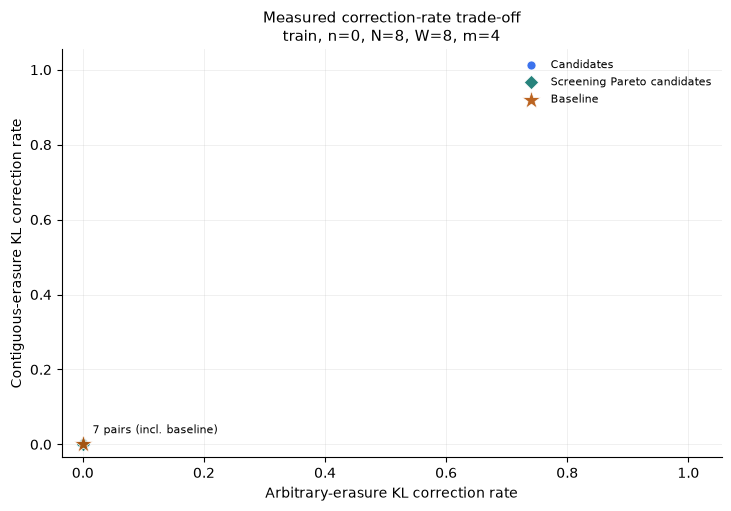

**design_score_vs_KL**

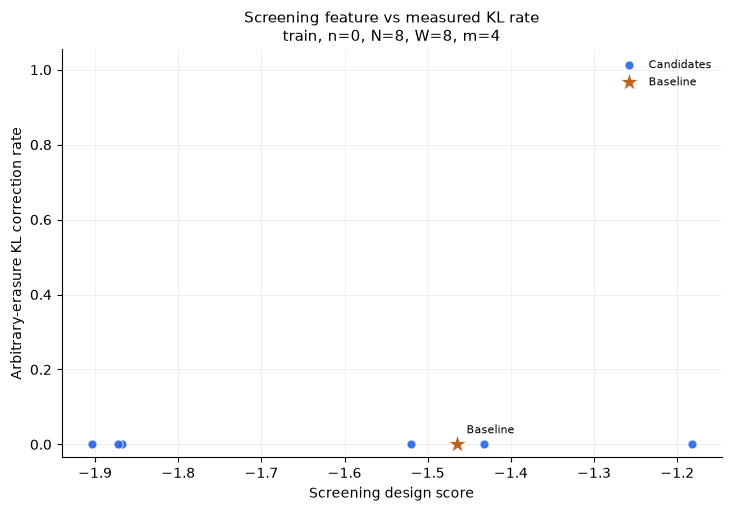

**d_cross_vs_KL**

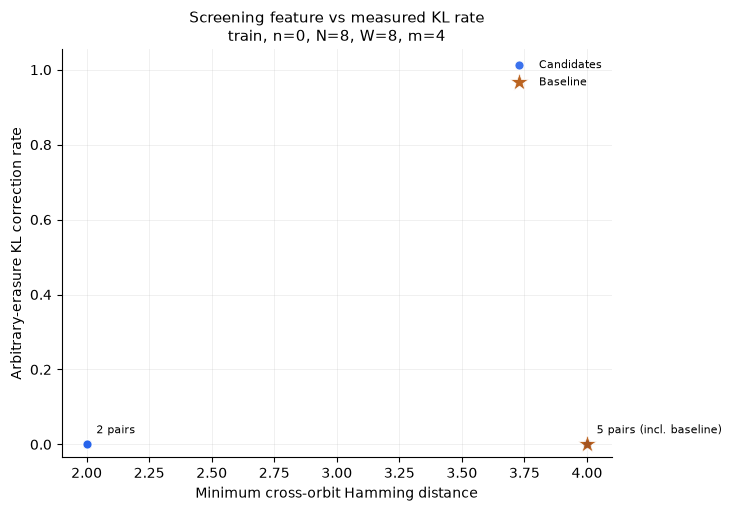

**collision_vs_KL**

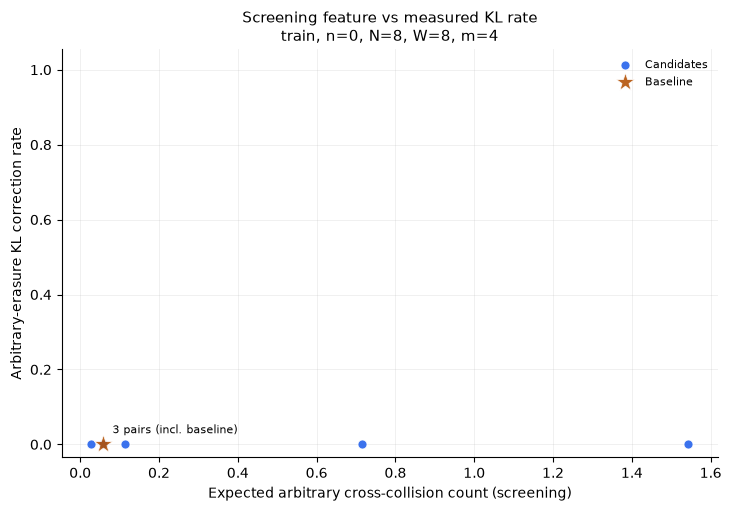

**sequence_feature_vs_KL**

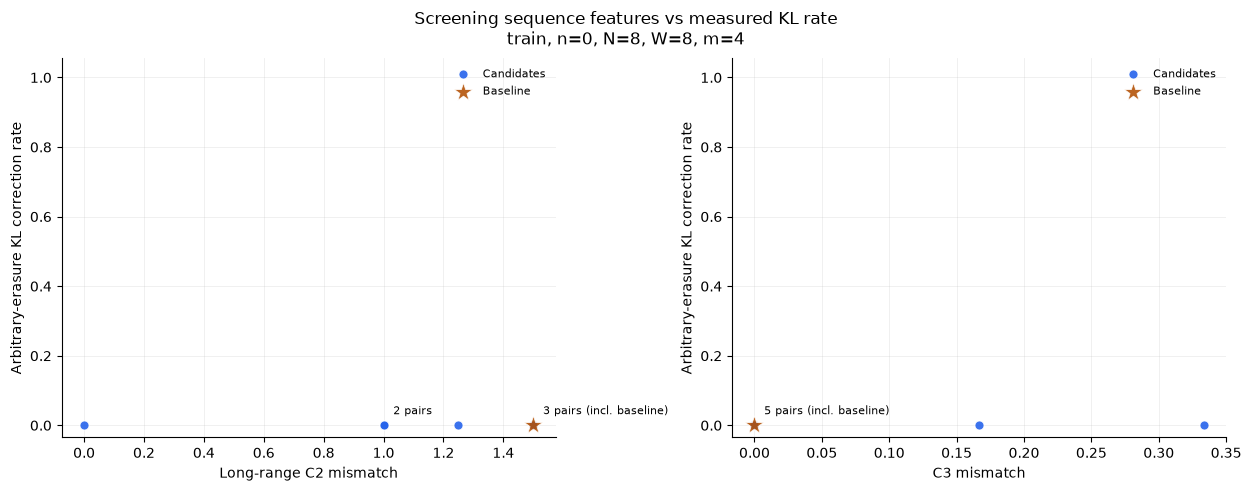

**leakage_vs_KL**

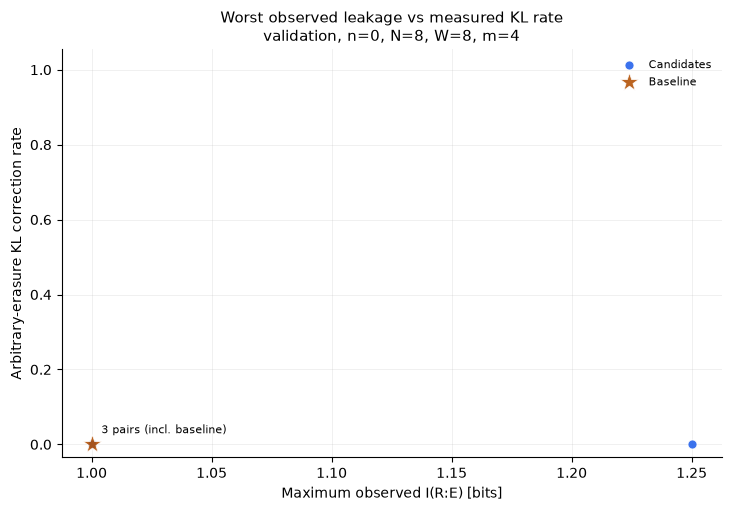

**baseline_vs_candidates**

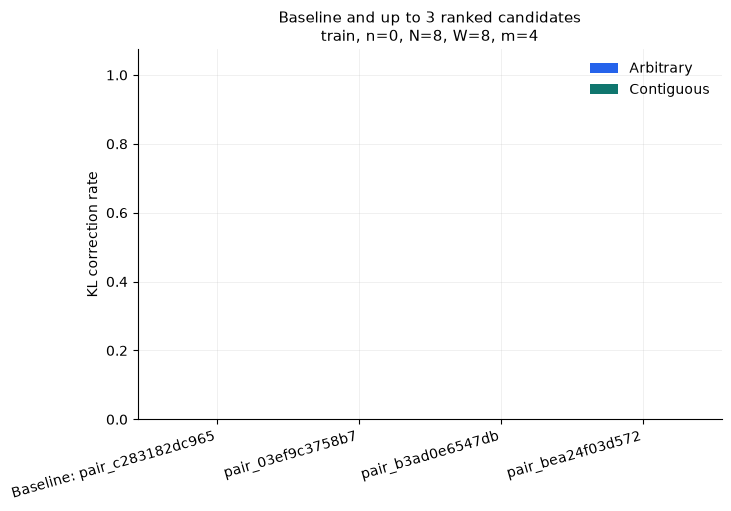

**candidate_performance_vs_m**

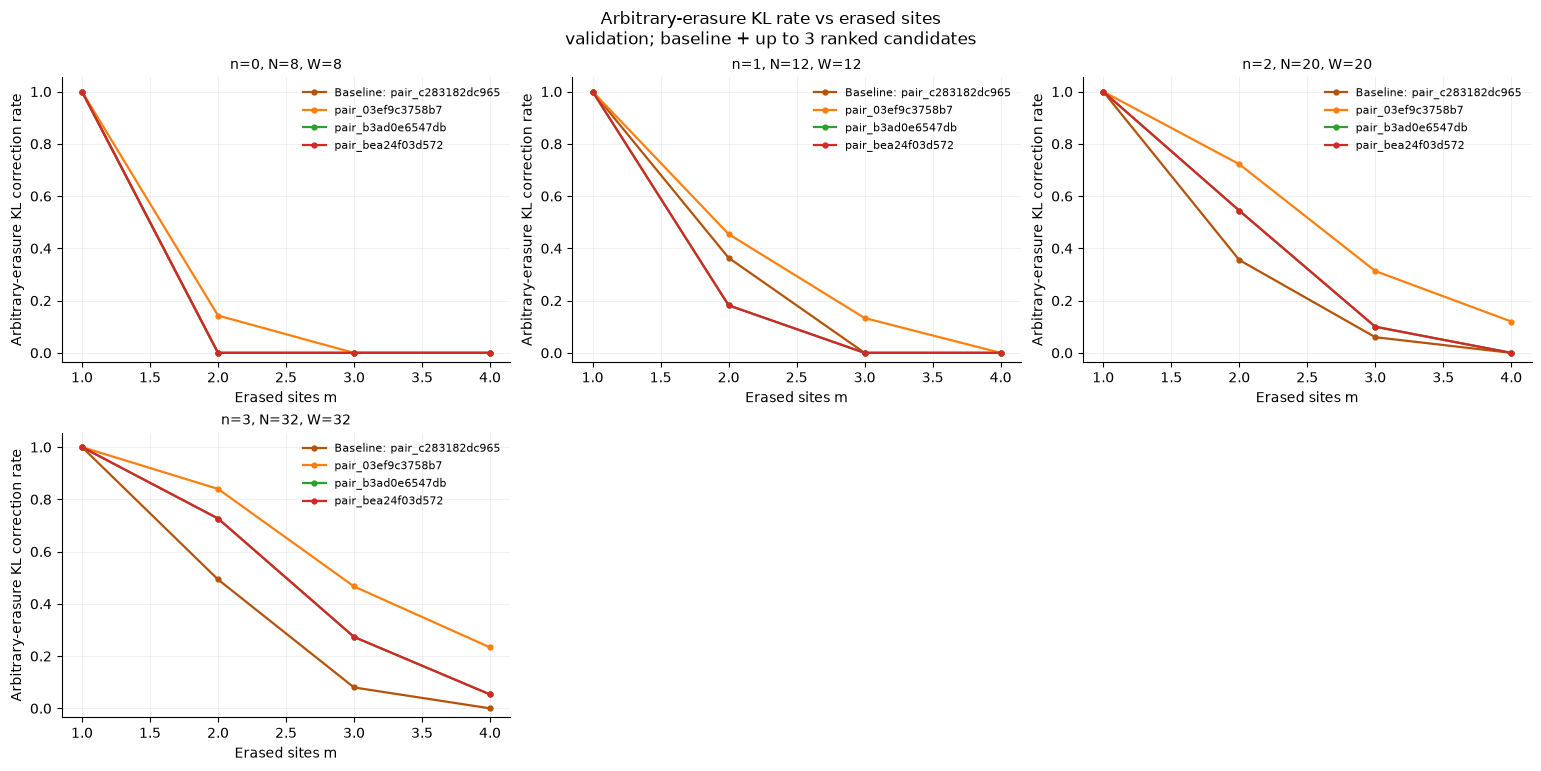

**candidate_performance_vs_N**

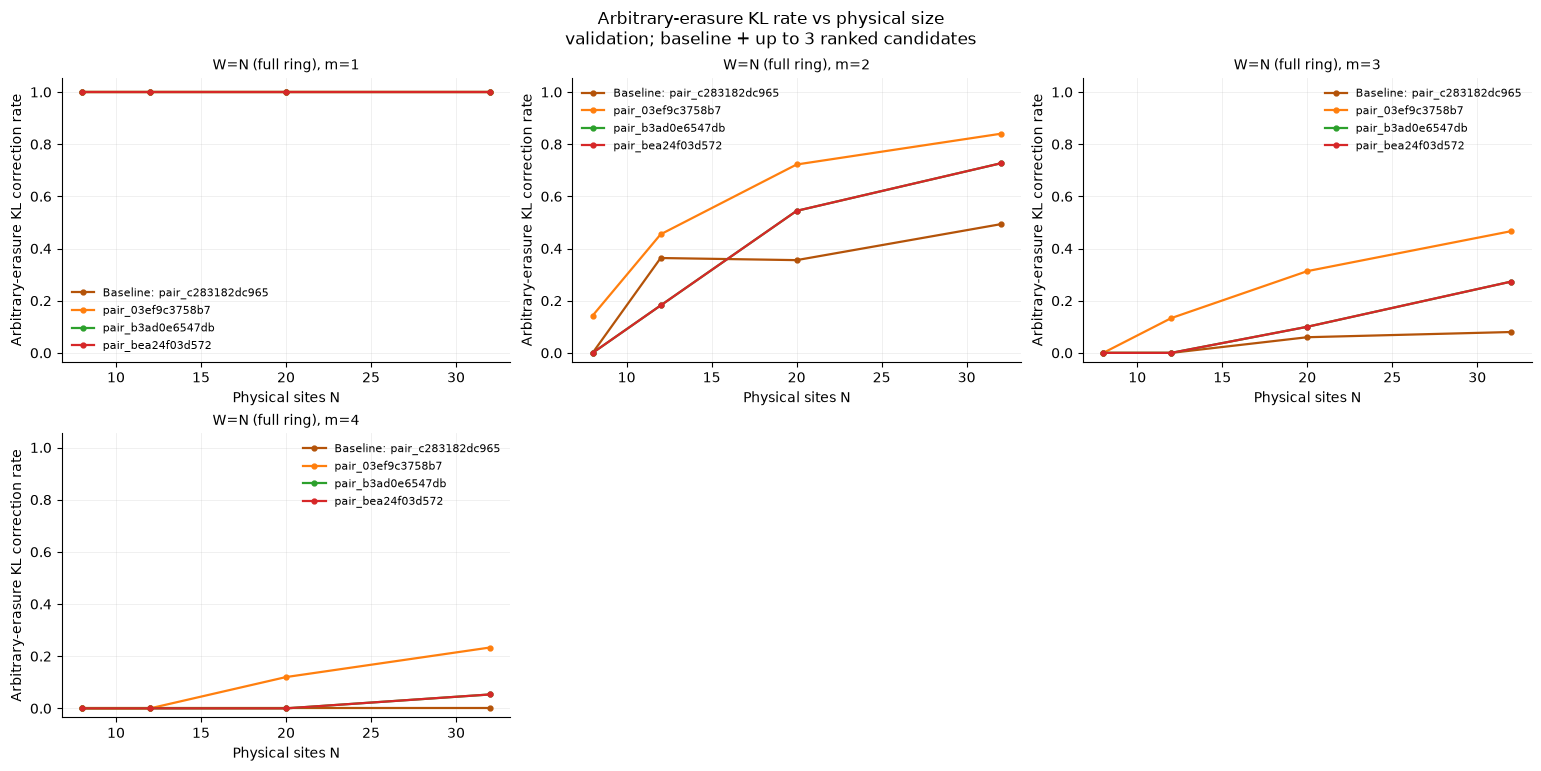

**candidate_improvement_vs_N**

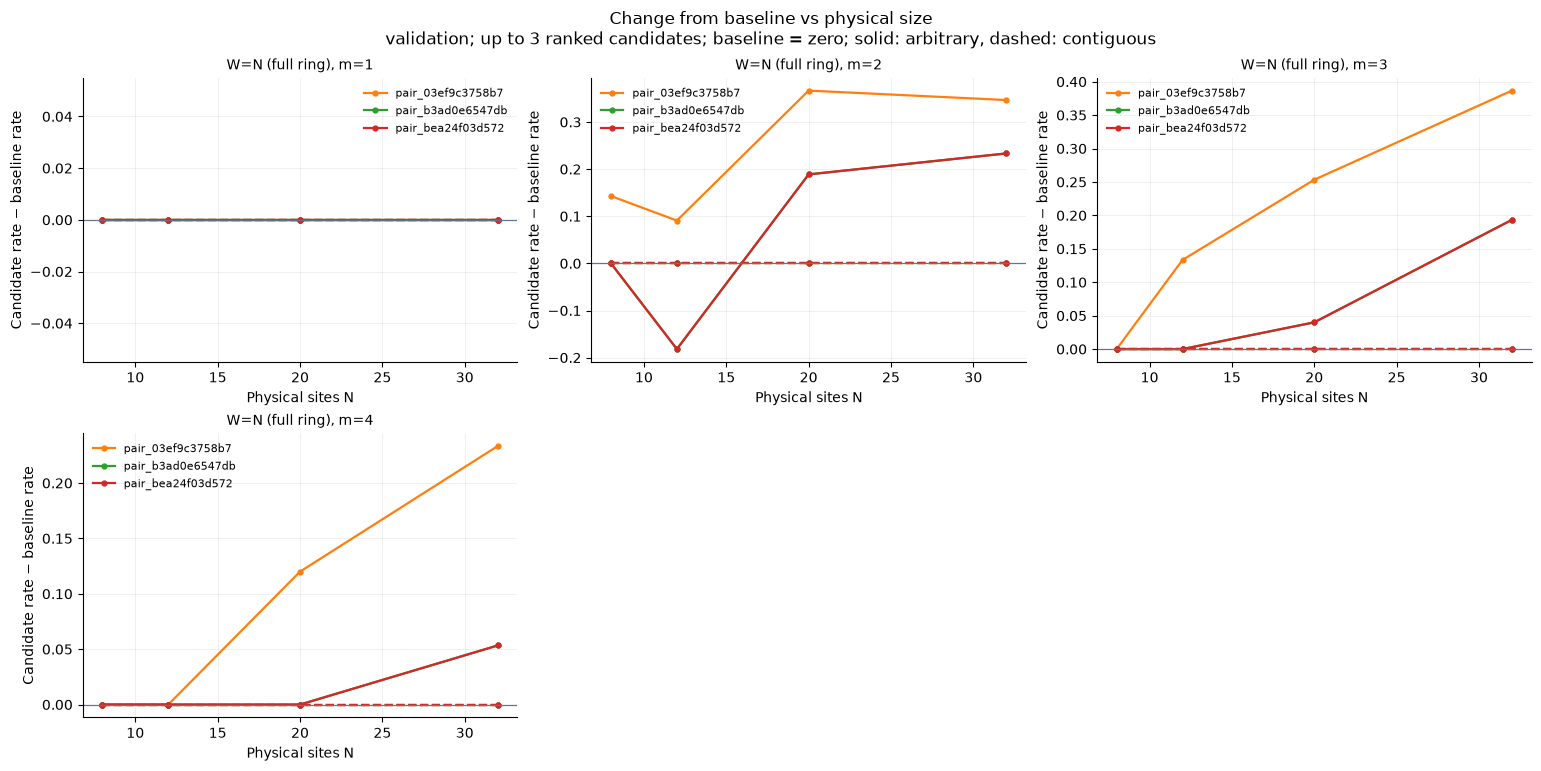

**improvement_vs_m**

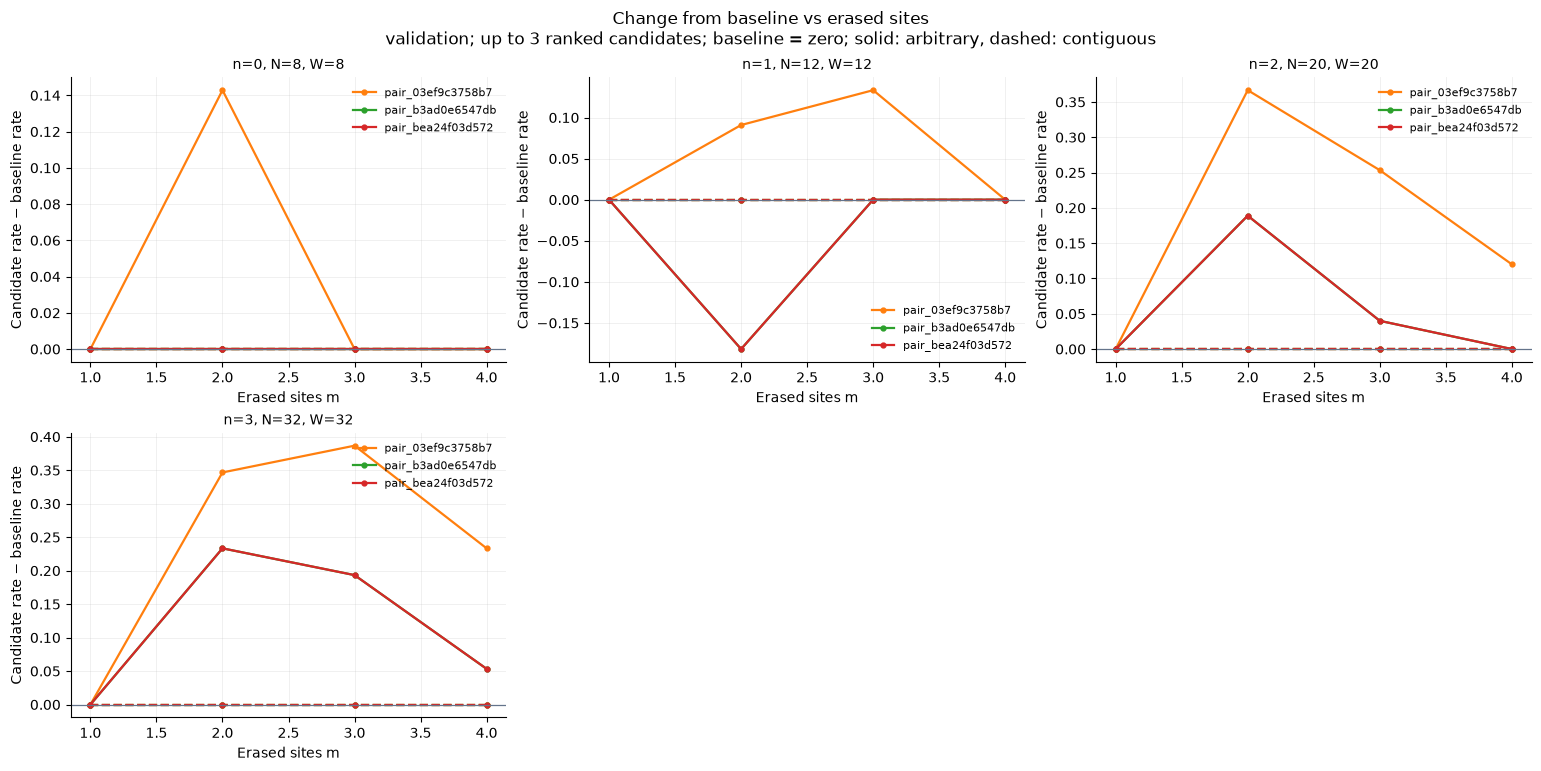

In [16]:
figures = make_figures(experiment.tables, Path(config.output_dir)/"figures",save=config.save_figures)
for name, figure in figures.items():
    display(Markdown(f"**{name}**"))
    display(figure)
    plt.close(figure)

## 27. 最終出力と保存

`results/` に候補、screening、KL、leakage、最終順位、baseline比較、collision spectrum、ablation、相関、benchmark、条件auditをCSV保存します。seed列を再読込するときは必ず `dtype={"seed_0": str, "seed_1": str}` を指定してください。

各candidate/条件ごとのJSON checkpointを原子的に保存し、同じ設定で再実行すると再利用します。sample一覧、manifest、validation前の選択も保存します。モデル・条件・mask hashを含むcache keyにより異なる実験の結果を混ぜません。`SAVE_RESULTS=False` では書き込みません。

旧CSVに必要な由来情報がない場合は自動的に信用せず参照用にします。元Notebookのモデル、正規化、領域定義、sample集合を確認してから変換してください。大規模研究用にserialを既定とし、独立なfeature taskはmultiprocessing可能です。

In [17]:
experiment.save()
display(pd.DataFrame([experiment.conclusion]))
print("Output directory:", Path(config.output_dir).resolve())
if config.save_results:
    for path in sorted((Path(config.output_dir)/"results").glob("*.csv")):
        print(path.name)

Output directory: /Users/ideryuito/Documents/Codex/2026-10-08/files-pasted-by-the-user-fibonacci/outputs/demo_run
code_design_KL_validation.csv
code_design_ablation.csv
code_design_aggregate.csv
code_design_baseline_comparison.csv
code_design_benchmark.csv
code_design_candidates.csv
code_design_collision_spectrum.csv
code_design_condition_audit.csv
code_design_correlations.csv
code_design_final_ranking.csv
code_design_leakage.csv
code_design_prior_inventory.csv
code_design_rejected.csv
code_design_screening.csv
code_design_validation_features.csv


,baseline,counts,passed_candidates,tested_validation_inflations,statement
0,"[00001111, 01010101]","{'raw_bit_strings': 70, 'number_cyclic_classes...",0,"[1, 2, 3]",Report only tested conditions; no untested can...


## 28. 結果の解釈：設計原理を検討する

Q1/Q8はKL改善と連続性能、Q2〜Q5はfeature・相関・ablation、Q6/Q7はN,m曲線で評価します。次セルでは候補ごとの差を並べます。

検証する仮説は「低weight support減少 → cross collision減少 → off-diagonal leakage低下 → KL改善」です。しかし対角KL不一致も独立の失敗原因です。相関や同時改善だけから因果関係を断定せず、反例も残します。local/long-range featureが変わらない場合、そのfeatureでは改善を説明できません。

sampledで有望でも、条件ごとの精度・leakageの標本数・全列挙可能性を確認してください。exactな性能結果は、その有限条件内に限って確定値です。改善なしの場合はseed lengthの拡張を次の実験とし、logical basis・振幅・位相・substitutionの変更は本Notebookの範囲外です。

In [18]:
base_features = screening[screening.is_baseline].iloc[0]
diagnostics=[]
for row in final_candidates.head(3).itertuples():
    feature = screening[screening.candidate_id==row.candidate_id].iloc[0]
    diagnostics.append({
        "candidate_id":row.candidate_id,
        "Delta_d_cross":feature.d_cross-base_features.d_cross,
        "Delta_low_weight_fraction":feature.low_weight_cross_support_fraction-base_features.low_weight_cross_support_fraction,
        "Delta_expected_collision":feature.expected_cross_collision_arbitrary-base_features.expected_cross_collision_arbitrary,
        "Delta_long_C2":feature.long_range_C2_mismatch-base_features.long_range_C2_mismatch,
        "Delta_C3":feature.C3_mismatch-base_features.C3_mismatch,
        "Delta_max_leakage_worst_condition":row.worst_leakage_change,
        "mean_Delta_R_arbitrary":row.average_arbitrary_improvement,
        "worst_Delta_R_contiguous":row.contiguous_change,
        "improving_N_count":row.improving_size_count,"improving_m_count":row.improving_m_count,
        "validation_pass":row.validation_pass,
    })
display(pd.DataFrame(diagnostics))
if not final_candidates.empty and final_candidates.validation_pass.any():
    display(Markdown("設定した有限の検証条件を通過したcandidateがあります。構造指標の変化と条件別表を照合し、説明できる点・説明できない点を分けて記録してください。"))
else:
    display(Markdown("**現設定で採用基準を通過したcandidateはありません。** 探索空間の制約、改善の条件依存、標本精度、leakage coverageのどれが原因かを理由列で確認してください。"))

,candidate_id,Delta_d_cross,Delta_low_weight_fraction,Delta_expected_collision,Delta_long_C2,Delta_C3,Delta_max_leakage_worst_condition,mean_Delta_R_arbitrary,worst_Delta_R_contiguous,improving_N_count,improving_m_count,validation_pass
0,pair_03ef9c3758b7,0,0.0,-0.028571,-0.5,0.0,0.229574,0.160909,0.0,3,3,False
1,pair_b3ad0e6547db,0,0.0,0.057143,0.0,0.0,NaN,0.043923,0.0,2,3,False
2,pair_bea24f03d572,0,0.0,0.000000,0.0,0.0,NaN,0.043923,0.0,2,3,False


**現設定で採用基準を通過したcandidateはありません。** 探索空間の制約、改善の条件依存、標本精度、leakage coverageのどれが原因かを理由列で確認してください。

### 実装と検証資料

`fibonacci_design/core.py`：隣接条件、正確KL、縮約状態、sampling。`features.py`：collision/sequence。`design.py`：探索・保存・最終判定。`report.py`：図表。

`python -m unittest -v test_fibonacci_design.py` で、小さい系のdense partial trace、全maskのKL、I(R:E)、collision期待値の全列挙、候補数、sampling、再開、CSV再利用を再検証できます。

出典：[有限Fibonacci構成](https://arxiv.org/html/2311.13040v2#A5)、[KL条件](https://arxiv.org/abs/quant-ph/9604034)。数式・surrogate・分類の実装上の定義は上記各節に明示しました。